In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from perseval.config import dataset_info

c:\Users\Guedes\Documentos\PersEval\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
plt.style.use('ggplot')

colors = {
    "EPIC": "#4C72B0",
    "BREXIT": "#DD8452",
    "MHS": "#55A868",
    "MD": "#C44E52",
    "DICES": "#8172B2"
}

In [4]:
df = pd.DataFrame.from_dict(dataset_info, orient='index')

## Metadata coverage per dataset

This heatmap shows which annotator **metadata fields** (e.g. age, gender, ethnicity, etc.) are available in each dataset's configuration. Each cell counts how many of those fields are populated, making it easy to spot which datasets provide richer demographic/contextual information about their annotators and which ones are more limited.

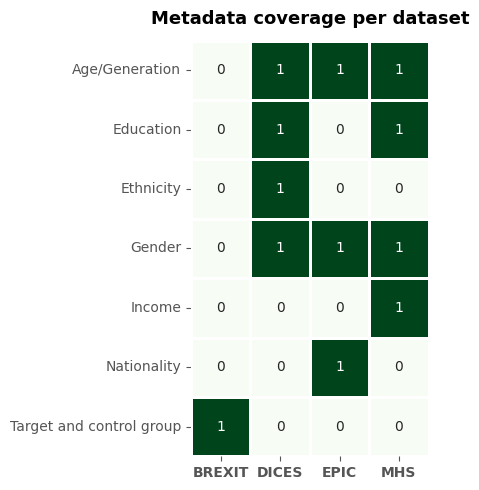

In [5]:
# Heatmap with metadata coverage per dataset
meta = df["metadata"].explode().dropna()
meta.index.name = "dataset"
coverage = pd.crosstab(meta, meta.index)

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(
    coverage,
    annot=True,
    fmt="d",
    cbar=False,
    cmap="Greens",
    linewidths=1,
    linecolor="white",
    square=True,
    ax=ax,

)
ax.set_title("Metadata coverage per dataset", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.setp(ax.get_xticklabels(), fontweight="bold")
plt.show()

## Dataset size statistics

These bar charts compare the five datasets along three key dimensions of their configuration: the number of **annotators**, the number of **texts** (unique items to be labeled), and the total number of **instances** (annotator-text pairs, i.e. individual annotations). Together they give a quick sense of the scale and annotation density of each dataset.

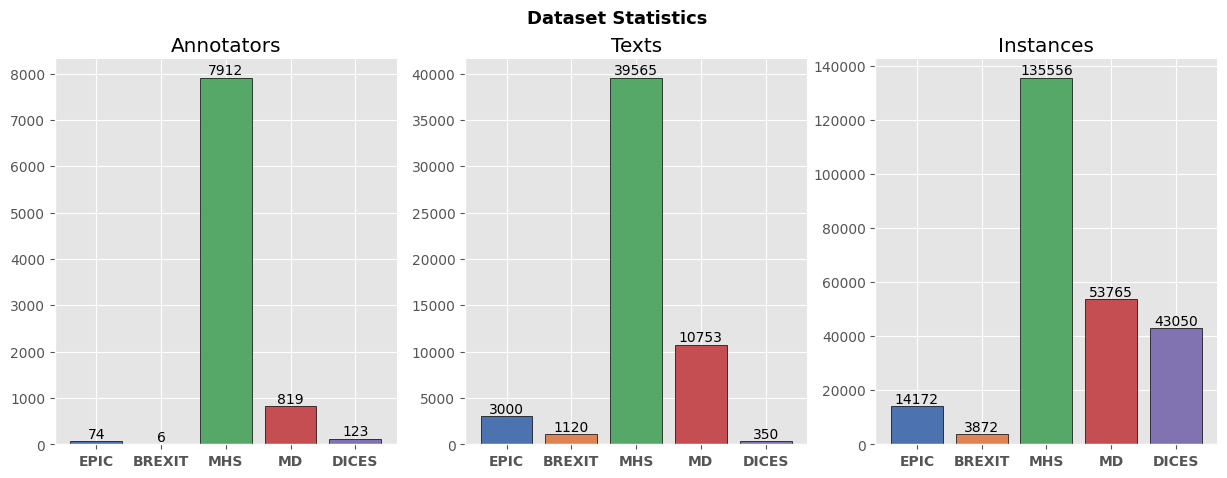

In [6]:
# Columns with numeric values of annotators, texts, and instances per dataset
numeric_df = df[["annotators", "texts", "instances"]]

fig, axs = plt.subplots(1,3, figsize=(15, 5))

for ax, column in zip(axs, numeric_df.columns):
    bars = ax.bar(numeric_df.index, numeric_df[column], color=[colors[dt] for dt in numeric_df.index], edgecolor="black", linewidth=0.5)
    ax.bar_label(bars)
    ax.set_title(column.title())
    ax.spines.top.set_visible(False)
    plt.setp(ax.get_xticklabels(), fontweight="bold")
    ax.spines.right.set_visible(False)
fig.suptitle("Dataset Statistics" , fontsize=13, fontweight="bold")
plt.show()

## Topic per dataset

This table summarizes the **annotation task** associated with each dataset's configuration (e.g. the type of label or judgment annotators were asked to provide). It gives a quick reference for understanding what each dataset was originally designed to measure.

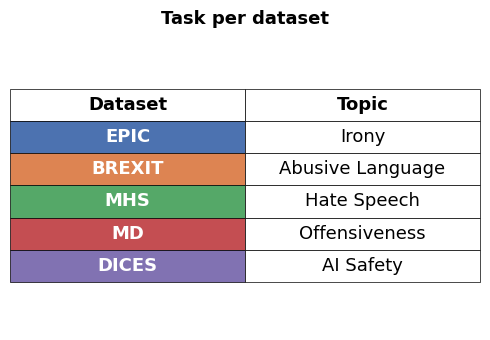

In [7]:
# Table: task per dataset
rows = list(dataset_info.keys())
cell_text = [[name, dataset_info[name]["task"]] for name in rows]
cell_colors = [[colors[name], "white"] for name in rows]

fig, ax = plt.subplots(figsize=(5, 1 + 0.5 * len(rows)))
ax.axis("off")

table = ax.table(
    cellText=cell_text,
    cellColours=cell_colors,
    colLabels=["Dataset", "Topic"],
    cellLoc="center",
    loc="center",
)
table.auto_set_font_size(False)
table.set_fontsize(13)
table.scale(1, 1.8)

for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_text_props(fontweight="bold")
    elif col == 0:
        cell.set_text_props(color="white", fontweight="bold")

ax.set_title("Task per dataset", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()